# B07 数字与类别混在一起，怎样预测房价？

在明确标注的模拟房屋数据上比较线性回归与梯度提升。理解不同列的预处理、未见类别和验证选型，输出一份可复算的测试预测表。

先修：B06；学习列选择、独热编码、列转换器与验证选型。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 生成有可解释机制的房屋数据
价格来自面积、房龄、区域及非线性面积效应，叠加噪声。真实房价不能由这个教学公式推断；我们使用它观察模型能否学到已知结构。缺失面积在生成价格后注入。

In [2]:
import numpy as np, pandas as pd, json
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
rng = np.random.default_rng(7); n = 800
houses = pd.DataFrame({'area': rng.uniform(35, 180, n), 'age': rng.integers(0, 45, n), 'district': rng.choice(['north','center','south'], n)})
prices = 80 + houses['area']*2.2 - houses['age']*1.2 + houses['district'].map({'north':20,'center':90,'south':0}) + 0.018*(houses['area']-100)**2 + rng.normal(0,12,n)
houses.loc[rng.choice(n, 35, replace=False), 'area'] = np.nan
houses.assign(price=prices).to_csv(DATA_DIR / 'simulated_houses.csv', index=False)
X_dev, X_test, y_dev, y_test = train_test_split(houses, prices, test_size=0.2, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=7)


## 2. 让每种列经过适当处理
数值缺失用训练中位数填充后标准化；类别变成独热列。`handle_unknown="ignore"` 让新区域不报错，但并不意味着模型已理解它。每次构造全新预处理器，避免两个模型共享可变状态。

In [3]:
def preprocessing():
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), ['area','age']),
        ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['district'])])
def make_models():
    return {'ridge': make_pipeline(preprocessing(), Ridge(alpha=1)),
            'boosting': make_pipeline(preprocessing(), HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=15, random_state=7))}
models = make_models()


## 3. 先验证选型，再锁定测试
同一行房屋用于公平比较；以验证 MAE 选推荐方案。两种方法均报告测试表现，但不能看到测试结果后重新选超参数。目标是学习有证据的选型，不保证复杂模型获胜。

In [4]:
val_scores = {}
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    val_scores[name] = float(mean_absolute_error(y_val, estimator.predict(X_val)))
selected = min(val_scores, key=val_scores.get)
predictions = pd.DataFrame({'actual': y_test.to_numpy()}, index=X_test.index)
for name, estimator in models.items():
    estimator.fit(X_dev, y_dev)
    predictions[name] = estimator.predict(X_test)
assert np.isfinite(predictions.to_numpy()).all()


## 4. 看误差，而不只看总分
保存预测与原始特征，检查大面积、新区域是否更容易出错。金额是任意教学单位；图的对角线表示完美预测。

In [5]:
metrics = {'selected_by_validation': selected, 'validation_mae': val_scores, 'test_mae': {name: float(mean_absolute_error(y_test, predictions[name])) for name in models}}
X_test.join(predictions).to_csv(OUT_DIR / 'predictions.csv', index=False)
(OUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
plt.scatter(y_test, predictions[selected], s=15, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='grey')
plt.xlabel('真实价格 / 教学单位'); plt.ylabel('预测价格'); plt.tight_layout(); plt.savefig(OUT_DIR / 'price_predictions.png'); plt.close(); print(metrics)


{'selected_by_validation': 'boosting', 'validation_mae': {'ridge': 29.377516458812316, 'boosting': 18.43812590797727}, 'test_mae': {'ridge': 28.349006127844724, 'boosting': 17.31136141207576}}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

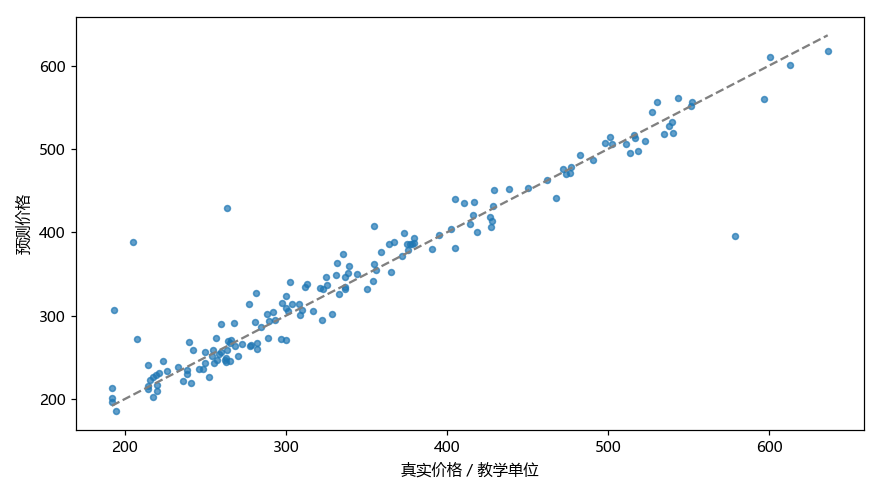

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
模拟结构不代表真实市场。所有预处理在训练折内拟合；不能在全数据算中位数后再切分。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。